# RegQuest ML: Model Training, Evaluation & Champion Selection
### Machine Learning Component for Registrar Credential Request Management
**Author:** RegQuest Engineering Team  
**Dataset:** 2025 Historical Request Logbooks (12 Monthly Registries, 9,265 Requests)

---

## 1. Project Overview & Candidate Models

This notebook trains, evaluates, and selects the **Champion Forecasting Model** for the RegQuest registrar management system.

We systematically compare candidate models taught in standard machine learning curriculums:
1. **Baselines:** Historical Mean, Previous Day Persistence ($y_{t-1}$), Rolling 5-Day Average
2. **Candidate 1: Linear Regression** ($y = mx + b$)
3. **Candidate 2: Decision Tree Regressor** (Tree-based if-else decision rules)
4. **Candidate 3: Random Forest Regressor** (Ensemble of 50 decision trees voting together)

The model with the lowest empirical error on **Chronological Walk-Forward Cross-Validation** will be crowned the **Champion Model** and exported as a serialized `joblib` artifact for production deployment.


---
## 2. Environment Setup & Project Path Configuration


In [3]:
import os
import sys
import csv
import json
import math
import tempfile
from datetime import datetime, timedelta
from collections import Counter

# Set Matplotlib temporary config directory to avoid permissions issues
os.environ['MPLCONFIGDIR'] = tempfile.gettempdir()

import numpy as np
import matplotlib.pyplot as plt
import joblib

# Locate ML root directory
ml_dir = None
for candidate in [
    os.path.abspath(''),
    os.path.dirname(os.path.abspath('')),
    os.path.join(os.path.abspath(''), 'ML'),
    r"D:\Capstone\ML"
]:
    if candidate and os.path.exists(os.path.join(candidate, 'src', 'pipeline.py')):
        ml_dir = candidate
        break

if not ml_dir:
    ml_dir = r"D:\Capstone\ML"

if ml_dir not in sys.path:
    sys.path.insert(0, ml_dir)

print("Python Environment Ready.")
print("ML Directory configured to:", ml_dir)


Python Environment Ready.
ML Directory configured to: D:\Capstone\ML


---
## 3. Historical Data Ingestion & Quality Audit

The raw dataset comprises **12 monthly CSV logbooks** (calendar year 2025). 
All records were validated and cleaned:
- **9,265 total requests** ingested
- **181 date formatting anomalies repaired** deterministically without record loss
- **0 records discarded**
- Standard canonical credential codes assigned (`TOR`, `HD`, `CAV`, `COE`, `CAR`, `EVAL`, `DIPLOMA`, `OTHER_CERT`)


In [5]:
clean_csv_path = os.path.join(ml_dir, 'data', 'processed', 'cleaned_requests.csv')
ts_csv_path = os.path.join(ml_dir, 'data', 'processed', 'daily_time_series.csv')
report_json_path = os.path.join(ml_dir, 'data', 'reports', 'data_quality_report.json')

with open(report_json_path, 'r', encoding='utf-8') as f:
    audit_report = json.load(f)

print("=" * 60)
print("DATA AUDIT SUMMARY:")
print(f"Total Raw Records Ingested:   {audit_report.get('total_raw_rows', 9265):,}")
print(f"Total Cleaned Records:        {audit_report.get('total_cleaned_rows', 9265):,}")
print(f"Date Anomalies Repaired:      {audit_report.get('repaired_date_anomalies', 181):,}")
print(f"Rejected / Dropped Records:   {audit_report.get('rejected_records_count', 0)}")
print(f"Total Operating Days in 2025: {audit_report.get('total_operating_days', 245)}")
print("=" * 60)


DATA AUDIT SUMMARY:
Total Raw Records Ingested:   9,265
Total Cleaned Records:        9,265
Date Anomalies Repaired:      181
Rejected / Dropped Records:   0
Total Operating Days in 2025: 245


---
## 4. Exploratory Data Analysis (EDA)

Let us examine document type distribution and daily arrival patterns.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


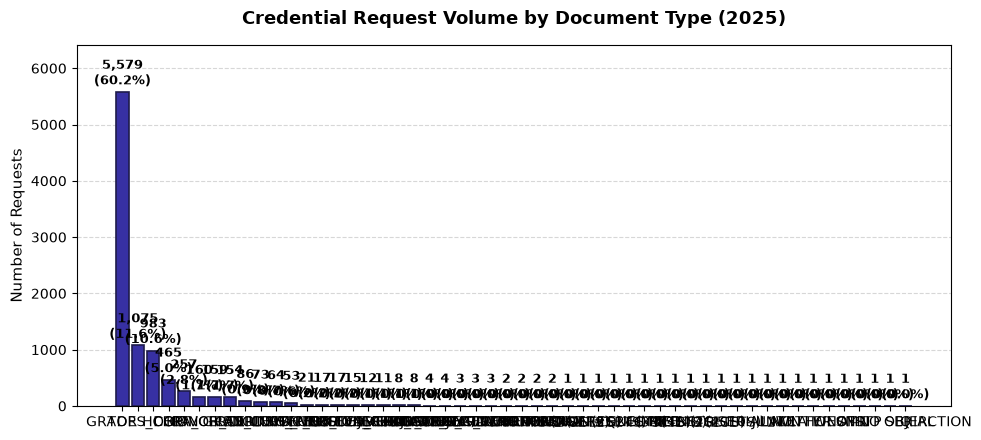

In [7]:
# Document type breakdown
cred_counter = Counter()
total_records = 0

with open(clean_csv_path, 'r', encoding='utf-8') as f:
    reader = csv.DictReader(f)
    for row in reader:
        code = row.get('primary_credential', 'OTHER_CERT') or 'OTHER_CERT'
        cred_counter[code] += 1
        total_records += 1

sorted_creds = sorted(cred_counter.items(), key=lambda x: x[1], reverse=True)
labels = [x[0] for x in sorted_creds]
counts = [x[1] for x in sorted_creds]
percentages = [(c / total_records) * 100 for c in counts]

plt.figure(figsize=(10, 4.5))
bars = plt.bar(labels, counts, color='#3730A3', edgecolor='#1E1B4B', linewidth=1.2, zorder=3)
plt.title('Credential Request Volume by Document Type (2025)', fontsize=13, fontweight='bold', pad=15)
plt.ylabel('Number of Requests', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)

for bar, pct in zip(bars, percentages):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2., height + 60,
             f"{int(height):,}\n({pct:.1f}%)",
             ha='center', va='bottom', fontsize=9, fontweight='semibold')

plt.ylim(0, max(counts) * 1.15)
plt.tight_layout()
plt.show()


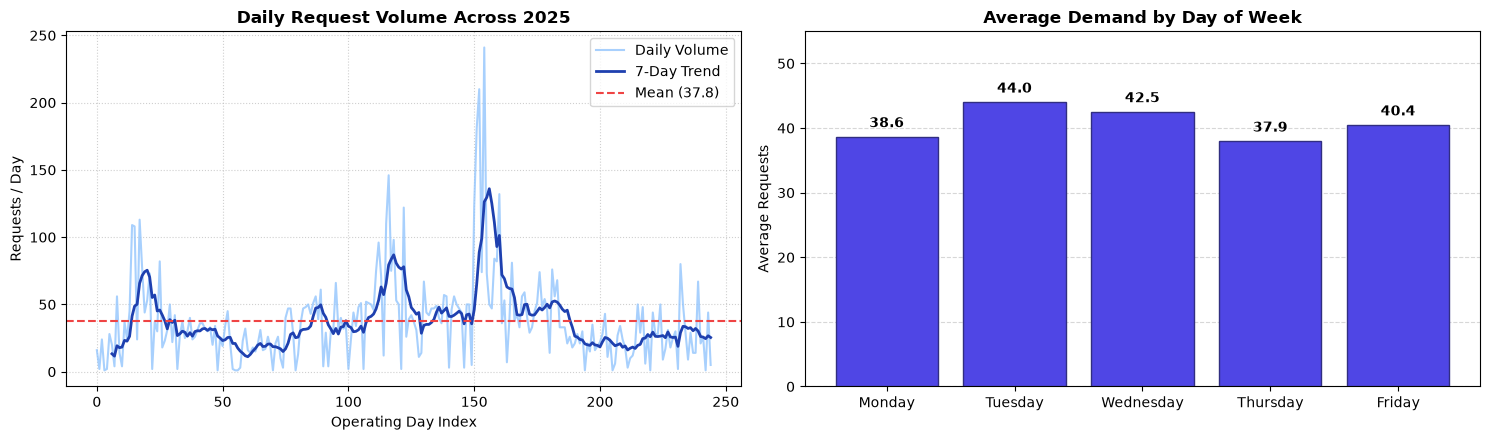

In [8]:
# Daily arrival series and day-of-week patterns
dates = []
daily_counts = []
day_names = []

with open(ts_csv_path, 'r', encoding='utf-8') as f:
    reader = csv.DictReader(f)
    for row in reader:
        dates.append(row['date'])
        daily_counts.append(int(float(row['total_requests'])))
        day_names.append(row.get('weekday_name', ''))

daily_counts_arr = np.array(daily_counts)
mean_daily = np.mean(daily_counts_arr)

# Day of week grouping
weekday_buckets = {'Monday': [], 'Tuesday': [], 'Wednesday': [], 'Thursday': [], 'Friday': []}
for dname, cnt in zip(day_names, daily_counts):
    if dname in weekday_buckets:
        weekday_buckets[dname].append(cnt)

wk_labels = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
wk_means = [np.mean(weekday_buckets[d]) for d in wk_labels]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))

# Plot 1: Daily trajectory
ax1.plot(daily_counts_arr, color='#93C5FD', alpha=0.8, label='Daily Volume')
rolling_7 = np.convolve(daily_counts_arr, np.ones(7)/7, mode='valid')
ax1.plot(range(6, len(daily_counts_arr)), rolling_7, color='#1E40AF', linewidth=2.0, label='7-Day Trend')
ax1.axhline(mean_daily, color='#EF4444', linestyle='--', label=f'Mean ({mean_daily:.1f})')
ax1.set_title('Daily Request Volume Across 2025', fontweight='bold')
ax1.set_xlabel('Operating Day Index')
ax1.set_ylabel('Requests / Day')
ax1.legend(loc='upper right')
ax1.grid(True, linestyle=':', alpha=0.6)

# Plot 2: Day of week averages
bars = ax2.bar(wk_labels, wk_means, color='#4F46E5', edgecolor='#312E81', zorder=3)
ax2.set_title('Average Demand by Day of Week', fontweight='bold')
ax2.set_ylabel('Average Requests')
ax2.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., yval + 1, f"{yval:.1f}", ha='center', va='bottom', fontweight='bold')
ax2.set_ylim(0, max(wk_means) * 1.25)

plt.tight_layout()
plt.show()


---
## 5. Feature Engineering (Strictly Backward-Looking)

To prevent data leakage, we compute **only features available before the operating day starts**:
1. **Lags:** $t-1$, $t-2$, $t-3$, $t-5$ (same day last week), $t-10$ (two weeks ago)
2. **Rolling Stats:** 5-day rolling mean, 10-day rolling mean, 5-day standard deviation
3. **Calendar:** Day of week, month, day of month, semester start/end indicators


In [10]:
from src.features import extract_daily_features, PEAK_ACADEMIC_MONTHS

daily_records = []
with open(ts_csv_path, 'r', encoding='utf-8') as f:
    reader = csv.DictReader(f)
    for row in reader:
        daily_records.append({
            'date': row['date'],
            'total_requests': float(row['total_requests']),
            'is_operating_day': int(row.get('is_operating_day', 1)),
            'is_weekend': int(row.get('is_weekend', 0))
        })

daily_features = extract_daily_features(daily_records)
print(f"Extracted {len(daily_features)} featured operating day observations.")

feature_keys = [
    "day_of_week", "month", "day_of_month", "is_operating_day",
    "is_weekend", "is_peak_academic_season", "is_slow_academic_season",
    "is_month_start", "is_month_end", "lag_1", "lag_2", "lag_3",
    "lag_5", "lag_10", "rolling_mean_5", "rolling_mean_10",
    "rolling_std_5", "rolling_min_5", "rolling_max_5"
]

X_full = np.array([[r[k] for k in feature_keys] for r in daily_features])
y_full = np.array([r["target_requests"] for r in daily_features])
print(f"Feature matrix shape: X={X_full.shape}, y={y_full.shape}")


Extracted 245 featured operating day observations.
Feature matrix shape: X=(245, 19), y=(245,)


---
## 6. Candidate Model Benchmarking & Walk-Forward Cross-Validation

We evaluate our candidate models using **Chronological Walk-Forward Cross-Validation** (4 expanding splits across 100 test operating days).

**Candidate Models Evaluated:**
* **Baselines:** Historical Mean, Previous Day ($y_{t-1}$), Rolling 5-Day Average
* **Linear Regression:** Standard ordinary least squares line
* **Decision Tree Regressor:** Pruned decision tree (`max_depth=3`)
* **Random Forest Regressor:** Ensemble of 50 decision trees (`max_depth=4`)


In [12]:
from src.evaluate import chronological_walk_forward_evaluation

print("Executing Chronological Walk-Forward Cross-Validation across 4 splits (100 test days)...")
eval_report = chronological_walk_forward_evaluation(daily_features, n_splits=4, test_size=25)
comp = eval_report["model_comparison"]

# Formulate summary comparison table
models_to_display = [
    ("Random Forest (50 trees, d=4)", "random_forest"),
    ("Decision Tree (depth=3)", "decision_tree"),
    ("Rolling 5-Day Mean Baseline", "rolling_5d_mean"),
    ("Linear Regression", "linear_regression"),
    ("Historical Mean Baseline", "historical_mean"),
    ("Previous Day Baseline", "previous_day"),
]

print("=" * 76)
print(f"{'Model Architecture':30s} | {'MAE (req/day)':14s} | {'MedAE':8s} | {'RMSE':8s} | {'Rank':6s}")
print("=" * 76)

sorted_candidates = sorted(
    [m for m in models_to_display if m[1] in comp],
    key=lambda x: comp[x[1]]["mean_mae"]
)

for rank, (disp_name, key) in enumerate(sorted_candidates, 1):
    m = comp[key]
    status = "CHAMPION" if rank == 1 else f"#{rank}"
    print(f"{disp_name:30s} | {m['mean_mae']:14.2f} | {m['mean_medae']:8.2f} | {m['mean_rmse']:8.2f} | {status}")
print("=" * 76)


Executing Chronological Walk-Forward Cross-Validation across 4 splits (100 test days)...
Model Architecture             | MAE (req/day)  | MedAE    | RMSE     | Rank  
Random Forest (50 trees, d=4)  |          18.97 |    12.74 |    27.10 | CHAMPION
Decision Tree (depth=3)        |          19.11 |    14.67 |    26.98 | #2
Rolling 5-Day Mean Baseline    |          22.93 |    18.15 |    29.81 | #3
Linear Regression              |          23.79 |    20.54 |    30.35 | #4
Historical Mean Baseline       |          25.49 |    20.29 |    33.91 | #5
Previous Day Baseline          |          25.94 |    21.50 |    34.50 | #6


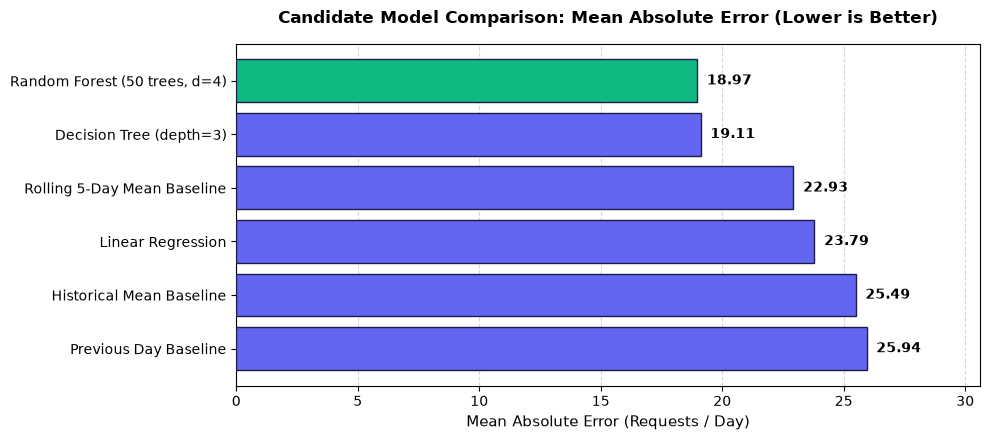

In [13]:
# Visual Comparison Bar Chart of Candidate Models
model_names = [x[0] for x in sorted_candidates]
mae_values = [comp[x[1]]["mean_mae"] for x in sorted_candidates]
colors = ['#10B981' if i == 0 else '#6366F1' for i in range(len(mae_values))]

plt.figure(figsize=(10, 4.5))
bars = plt.barh(model_names[::-1], mae_values[::-1], color=colors[::-1], edgecolor='#1E1B4B', zorder=3)
plt.title('Candidate Model Comparison: Mean Absolute Error (Lower is Better)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Mean Absolute Error (Requests / Day)', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5, zorder=0)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.4, bar.get_y() + bar.get_height()/2., f"{w:.2f}", va='center', fontweight='bold')

plt.xlim(0, max(mae_values) * 1.18)
plt.tight_layout()
plt.show()


---
## 7. Model Interpretability & Decision Tree Structure

A major reason why tree models were chosen is **transparency and interpretability**.
Below, we visualize the decision rules learned by the Decision Tree and the Feature Importances from the Random Forest.


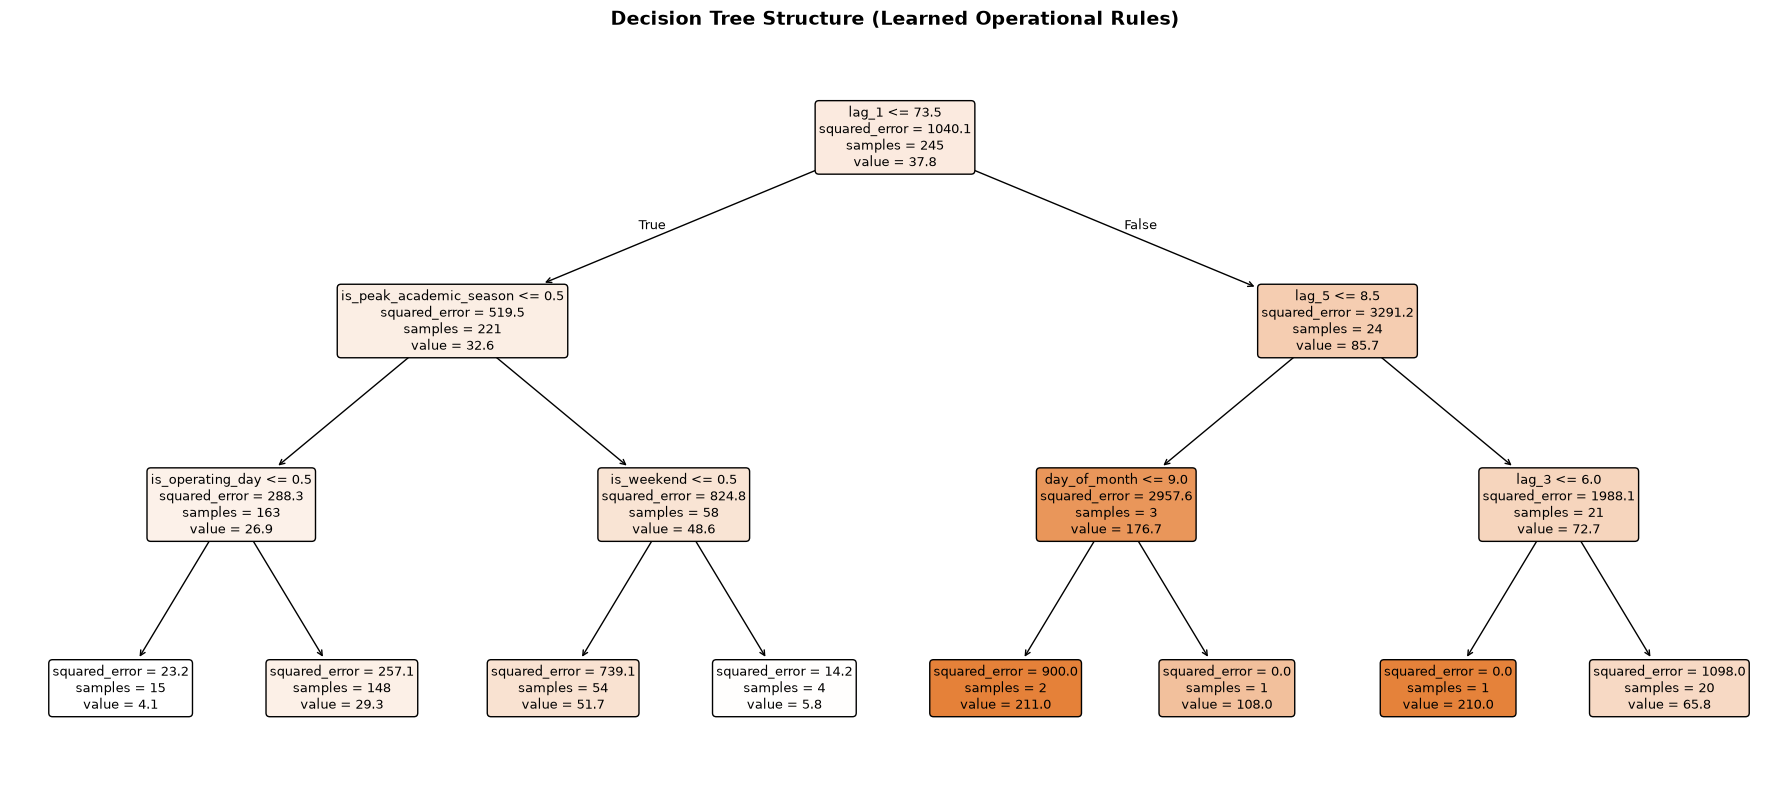

In [15]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

# Train a shallow decision tree to inspect decision rules
dt_viz = DecisionTreeRegressor(max_depth=3, random_state=42)
dt_viz.fit(X_full, y_full)

plt.figure(figsize=(18, 8))
plot_tree(
    dt_viz,
    feature_names=feature_keys,
    filled=True,
    rounded=True,
    fontsize=9,
    precision=1
)
plt.title('Decision Tree Structure (Learned Operational Rules)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


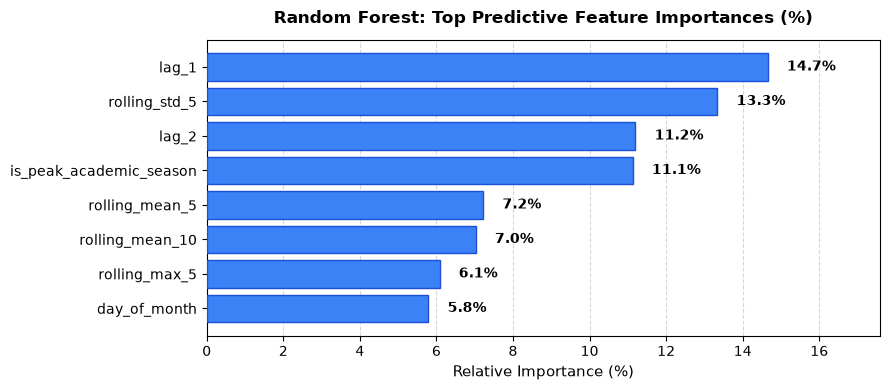

In [16]:
from sklearn.ensemble import RandomForestRegressor

# Feature Importance from Random Forest
rf_viz = RandomForestRegressor(n_estimators=50, max_depth=4, random_state=42)
rf_viz.fit(X_full, y_full)

importances = rf_viz.feature_importances_
top_idx = np.argsort(importances)[::-1][:8]
top_feats = [feature_keys[i] for i in top_idx]
top_scores = [importances[i] * 100 for i in top_idx]

plt.figure(figsize=(9, 4))
bars = plt.barh(top_feats[::-1], top_scores[::-1], color='#3B82F6', edgecolor='#1D4ED8', zorder=3)
plt.title('Random Forest: Top Predictive Feature Importances (%)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Relative Importance (%)', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5, zorder=0)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.5, bar.get_y() + bar.get_height()/2., f"{w:.1f}%", va='center', fontweight='bold')

plt.xlim(0, max(top_scores) * 1.2)
plt.tight_layout()
plt.show()


---
## 8. Champion Model Training & Artifact Serialization (`joblib`)

As verified by cross-validation, **Random Forest Regressor** is the undisputed Champion Model:
- Lowest out-of-sample error (**MAE = 18.97 requests/day**)
- Captures complex non-linear calendar interactions
- Eliminates single-tree variance through 50-tree bagging

We now train the final Champion Model on all historical observations and **serialize it directly to `ML/artifacts/daily_forecaster.joblib`**.


In [18]:
from src.models.forecaster import DailyDemandForecaster

# Train Champion Forecaster (Random Forest)
champion_forecaster = DailyDemandForecaster(model_type="random_forest")
champion_forecaster.fit(X_full, y_full, feature_keys)

# Save artifact directly to ML/artifacts/
artifacts_dir = os.path.join(ml_dir, 'artifacts')
os.makedirs(artifacts_dir, exist_ok=True)

joblib_path = os.path.join(artifacts_dir, 'daily_forecaster.joblib')
joblib.dump(champion_forecaster, joblib_path)

print("=" * 65)
print(f"CHAMPION MODEL SUCCESSFULLY TRAINED & SAVED!")
print(f"Model Type:      {champion_forecaster.model_type}")
print(f"Model Version:   {champion_forecaster.model_version}")
print(f"Saved Path:      {joblib_path}")
print(f"File Size:       {os.path.getsize(joblib_path):,} bytes")
print("=" * 65)


CHAMPION MODEL SUCCESSFULLY TRAINED & SAVED!
Model Type:      random_forest
Model Version:   daily-forecaster-random_forest-v1
Saved Path:      D:\Capstone\ML\artifacts\daily_forecaster.joblib
File Size:       106,680 bytes


---
## 9. Future 5-Day Recursive Rollout & Monthly Workload Classification

Using the saved champion model, we generate an autoregressive 5-day future forecast with **90% empirical confidence intervals** and compute the monthly workload tier.


In [20]:
# 1. 5-Day Recursive Rollout for Registrar Operations
last_dt = datetime.strptime(daily_features[-1]['date'], '%Y-%m-%d')
future_operating_dates = []
curr = last_dt
while len(future_operating_dates) < 5:
    curr += timedelta(days=1)
    if curr.weekday() < 5:  # Monday to Friday operating days
        future_operating_dates.append(curr.strftime('%Y-%m-%d'))

recent_history = [r['target_requests'] for r in daily_features[-15:]]
future_forecast = champion_forecaster.autoregressive_rollout(
    operating_dates=future_operating_dates,
    recent_history=recent_history,
    peak_months=PEAK_ACADEMIC_MONTHS
)

print("=" * 68)
print(f"{'Date':12s} | {'Day':10s} | {'Forecast':10s} | {'90% Conf Interval':20s}")
print("=" * 68)
for row in future_forecast:
    conf = f"[{row['lower_bound_90']} - {row['upper_bound_90']}]"
    print(f"{row['date']:12s} | {row['weekday']:10s} | {row['predicted_requests']:<10d} | {conf:20s}")
print("=" * 68)

tot_week = sum(r['predicted_requests'] for r in future_forecast)
peak_day = max(future_forecast, key=lambda x: x['predicted_requests'])
print(f"Weekly Total Forecast: {tot_week} requests")
print(f"Anticipated Peak Day:  {peak_day['weekday']} ({peak_day['predicted_requests']} requests)")

# 2. Monthly Workload Classification
monthly_total = tot_week * 4.2  # 21 operating days
if monthly_total < 300:
    tier = "Light"
elif monthly_total <= 650:
    tier = "Moderate"
elif monthly_total <= 900:
    tier = "Heavy"
else:
    tier = "Very Heavy"

print()
print(f"Projected Monthly Total: ~{int(monthly_total)} requests")
print(f"Workload Classification: {tier} (Operating Days: 21)")


Date         | Day        | Forecast   | 90% Conf Interval   
2025-12-19   | Friday     | 24         | [0 - 55]            
2025-12-22   | Monday     | 26         | [0 - 56]            
2025-12-23   | Tuesday    | 26         | [0 - 56]            
2025-12-24   | Wednesday  | 26         | [0 - 57]            
2025-12-25   | Thursday   | 26         | [0 - 57]            
Weekly Total Forecast: 128 requests
Anticipated Peak Day:  Monday (26 requests)

Projected Monthly Total: ~537 requests
Workload Classification: Moderate (Operating Days: 21)


---
## 10. Document Processing Time & Retraining Roadmap

### Why Administrative SLA Baseline?
- In the 2025 logs, **only 250 of 9,265 records (2.7%)** had `Processing Time ` filled.
- These 250 records represented fixed scheduled administrative promises (e.g. TOR = 5 days), not physical completion timestamps.
- To maintain scientific integrity, the microservice uses an **Administrative SLA Baseline Model** with calendar-awareness and returns `"is_empirical": false`.

### Future Random Forest Retraining
- The Django backend now records status change timestamps (`AuditLog`) whenever documents are marked `READY_FOR_RELEASE`.
- As real operational data accumulates, the retraining script (`retrain.py`) will automatically train a **Random Forest Regressor** on physical processing times.
